<a href="https://colab.research.google.com/github/pedrohenriquebarros92/AI_ML---Aprendizagem-supervisionada-e-n-o-supervisionada/blob/main/AI_Aprendizagem_supervisionada_Pr%C3%A1tica_com_5_algor%C3%ADtmos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 📚 Aprendizagem Supervisionada - Prática com 5 Algoritmos

**Módulo 1 — Inteligência Artificial**  
**Aula 04 — Aprendizagem Supervisionada**  
**Professor: Heuryk Wylk**

**Alunos: Marcelo Barbosa, Pedro Henrique Barros e Wendel Brasiliano**

---

## 🎯 Objetivo

Este notebook acompanha a Aula 04 e permite praticar os **5 algoritmos supervisionados mais usados em produção**:

1. **Regressão Linear** - prever números (regressão)
2. **Regressão Logística** - classificar categorias (classificação)
3. **Árvore de Decisão** - regras if/else aprendidas
4. **Random Forest** - ensemble de árvores (robusto)
5. **XGBoost** - gradient boosting (campeão de benchmarks)

## 🗂️ Datasets usados

- **Regressão**: California Housing - prever o preço médio de casas na Califórnia
- **Classificação**: Breast Cancer Wisconsin - prever se tumor é maligno ou benigno

## ⏱️ Tempo estimado

60-90 minutos. Vá no seu ritmo, leia os comentários e tente entender o que cada linha faz.

---

## 1. Setup - Instalação e Imports

Se você está rodando localmente, talvez precise instalar algumas bibliotecas:

```bash
pip install scikit-learn numpy pandas matplotlib seaborn xgboost
```

Em seguida, importe o que vamos usar.

In [ ]:
# Imports principais
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-learn: datasets, split, modelos e métricas
from sklearn.datasets import fetch_california_housing, load_breast_cancer
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score,
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score
)

# Configuração de visualização
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('husl')
%matplotlib inline
np.random.seed(42)

print('✅ Ambiente pronto! Versões:')
print(f'  NumPy:      {np.__version__}')
print(f'  Pandas:     {pd.__version__}')
import sklearn, xgboost
print(f'  Scikit-learn: {sklearn.__version__}')
print(f'  XGBoost:    {xgboost.__version__}')

✅ Ambiente pronto! Versões:
  NumPy:      2.1.3
  Pandas:     2.2.3
  Scikit-learn: 1.6.1
  XGBoost:    3.4.1


---
## 2. Regressão Linear

**O que faz:** prevê um número contínuo (preço, demanda, temperatura).

**Quando usar:** relação linear entre entrada e saída, baseline em qualquer projeto.

**Dataset:** California Housing - 8 features (renda média, idade da casa, número de quartos etc.) para prever o **preço médio** de casas em diferentes regiões da Califórnia.

In [ ]:
# Carregar o dataset California Housing para o problema de regressão.
housing = fetch_california_housing(as_frame=True)

# Criar um DataFrame com as variáveis de entrada (features).
df_housing = housing.frame.copy()

# Separar as features (X) do alvo (y), que é o valor médio das casas.
X = df_housing.drop(columns=[housing.target_names[0]])
y = df_housing[housing.target_names[0]]

# Mostrar as primeiras linhas para conferir se os dados foram carregados corretamente.
print(f"Quantidade de registros: {len(df_housing)}")
print(f"Quantidade de features: {X.shape[1]}")
print(f"Nome do alvo: {housing.target_names[0]}")
display(df_housing.head())


Quantidade de registros: 20640
Quantidade de features: 8
Nome do alvo: MedHouseVal


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [ ]:
# Verificar informações básicas do dataset.
print("Dimensões:", df_housing.shape)
print("\nValores ausentes por coluna:")
print(df_housing.isnull().sum())

# Exibir estatísticas descritivas das variáveis numéricas.
display(df_housing.describe().round(2))

# Mostrar a correlação entre as features e o preço médio.
correlacoes = df_housing.corr(numeric_only=True)[housing.target_names[0]].sort_values(ascending=False)
print("\nCorrelação com o preço médio:")
display(correlacoes.to_frame(name='correlacao'))


Dimensões: (20640, 9)

Valores ausentes por coluna:
MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00
mean,3.87,28.64,5.43,1.10,1425.48,3.07,35.63,-119.57,2.07
std,1.90,12.59,2.47,0.47,1132.46,10.39,2.14,2.00,1.15
min,0.50,1.00,0.85,0.33,3.00,0.69,32.54,-124.35,0.15
25%,2.56,18.00,4.44,1.01,787.00,2.43,33.93,-121.80,1.20
50%,3.53,29.00,5.23,1.05,1166.00,2.82,34.26,-118.49,1.80
75%,4.74,37.00,6.05,1.10,1725.00,3.28,37.71,-118.01,2.65
max,15.00,52.00,141.91,34.07,35682.00,1243.33,41.95,-114.31,5.00



Correlação com o preço médio:


,correlacao
MedHouseVal,1.000000
MedInc,0.688075
AveRooms,0.151948
HouseAge,0.105623
AveOccup,-0.023737
Population,-0.024650
Longitude,-0.045967
AveBedrms,-0.046701
Latitude,-0.144160


### 2.1. Split treino/teste

Regra de ouro: nunca treine no mesmo dado que vai testar. Aqui usamos 80/20.

In [ ]:
# Dividir os dados em 80% para treino e 20% para teste.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

# Conferir o tamanho dos conjuntos.
print(f"Treino: {X_train.shape[0]} registros")
print(f"Teste:  {X_test.shape[0]} registros")


Treino: 16512 registros
Teste:  4128 registros


### 2.2. Treinar e avaliar o modelo

In [ ]:
# Instanciar o modelo de Regressão Linear.
modelo_lr = LinearRegression()

# Treinar o modelo somente com os dados de treino.
modelo_lr.fit(X_train, y_train)

# Predizer os preços no conjunto de teste.
y_pred = modelo_lr.predict(X_test)

# Calcular as principais métricas de regressão.
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"MAE:  {mae:.4f}")
print(f"MSE:  {mse:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R²:   {r2:.4f}")


MAE:  0.5332
MSE:  0.5559
RMSE: 0.7456
R²:   0.5758


In [ ]:
# Criar uma tabela com os coeficientes de cada feature.
coeficientes = pd.DataFrame({
    'feature': X.columns,
    'coeficiente': modelo_lr.coef_
}).sort_values('coeficiente', key=np.abs, ascending=False)

display(coeficientes)


,feature,coeficiente
3,AveBedrms,0.783145
0,MedInc,0.448675
7,Longitude,-0.433708
6,Latitude,-0.419792
2,AveRooms,-0.123323
1,HouseAge,0.009724
5,AveOccup,-0.003526
4,Population,-0.000002


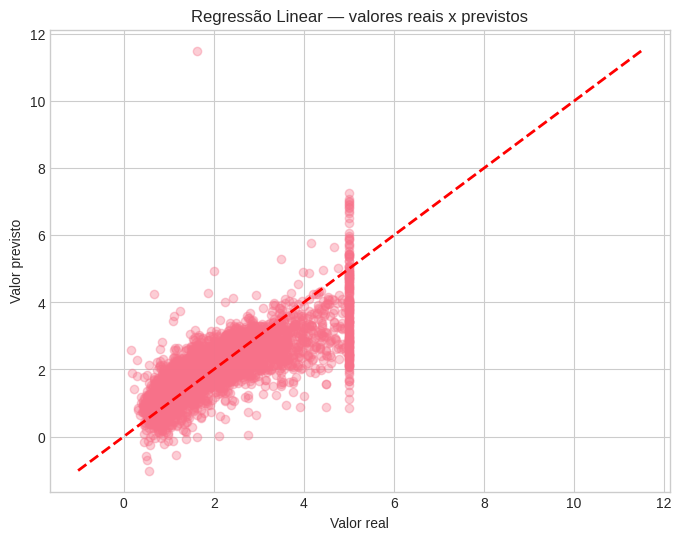

In [ ]:
# Visualizar os valores reais e as predições do modelo.
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.35)

# A linha de referência representa a situação ideal: predição = valor real.
limite_min = min(y_test.min(), y_pred.min())
limite_max = max(y_test.max(), y_pred.max())
plt.plot([limite_min, limite_max], [limite_min, limite_max], 'r--', linewidth=2)

plt.xlabel('Valor real')
plt.ylabel('Valor previsto')
plt.title('Regressão Linear — valores reais x previstos')
plt.show()


**Interpretação:** cada ponto é um bairro. Quanto mais perto da linha vermelha, melhor a predição. Pontos espalhados = modelo erra mais. Regressão Linear é simples - aqui R² = 0.58 significa que o modelo explica 58% da variação do preço.

---
## 3. Regressão Logística

**O que faz:** classifica em 2 ou mais categorias. A saída é uma **probabilidade** (0 a 1).

**Quando usar:** classificação binária (sim/não, fraude/não fraude, churn/não churn).

**Dataset:** Breast Cancer Wisconsin - 30 features de imagens de tumores para prever se é **maligno** ou **benigno** (o dataset do scikit-learn usa 0 = maligno e 1 = benigno).

In [ ]:
# Carregar o dataset Breast Cancer Wisconsin para classificação binária.
cancer = load_breast_cancer(as_frame=True)

# X contém as 30 features e y contém a classe do tumor.
X_cancer = cancer.data.copy()
y_cancer = cancer.target.copy()

# No dataset do scikit-learn: 0 = maligno e 1 = benigno.
print("Classes:", dict(enumerate(cancer.target_names)))
print(f"Registros: {X_cancer.shape[0]}")
print(f"Features: {X_cancer.shape[1]}")


Classes: {0: np.str_('malignant'), 1: np.str_('benign')}
Registros: 569
Features: 30


In [ ]:
# Dividir os dados mantendo a proporção das classes com stratify.
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X_cancer, y_cancer, test_size=0.20, random_state=42, stratify=y_cancer
)

# Criar o padronizador: média 0 e desvio padrão 1.
scaler = StandardScaler()

# Ajustar o scaler somente no treino e transformar treino e teste.
X_train_scaled = scaler.fit_transform(X_train_c)
X_test_scaled = scaler.transform(X_test_c)

print(f"Treino: {X_train_scaled.shape[0]} registros")
print(f"Teste:  {X_test_scaled.shape[0]} registros")


Treino: 455 registros
Teste:  114 registros


In [ ]:
# Instanciar a Regressão Logística.
modelo_log = LogisticRegression(max_iter=5000, random_state=42)

# Treinar com os dados padronizados.
modelo_log.fit(X_train_scaled, y_train_c)

# Predizer as classes do conjunto de teste.
y_pred_log = modelo_log.predict(X_test_scaled)

# Obter a probabilidade da classe positiva (1 = benigno).
y_prob_log = modelo_log.predict_proba(X_test_scaled)[:, 1]

# Calcular as métricas de classificação.
accuracy_log = accuracy_score(y_test_c, y_pred_log)
precision_log = precision_score(y_test_c, y_pred_log)
recall_log = recall_score(y_test_c, y_pred_log)
f1_log = f1_score(y_test_c, y_pred_log)
auc_log = roc_auc_score(y_test_c, y_prob_log)

print(f"Accuracy:  {accuracy_log:.4f}")
print(f"Precision: {precision_log:.4f}")
print(f"Recall:    {recall_log:.4f}")
print(f"F1-score:  {f1_log:.4f}")
print(f"AUC:       {auc_log:.4f}")


Accuracy:  0.9825
Precision: 0.9861
Recall:    0.9861
F1-score:  0.9861
AUC:       0.9954


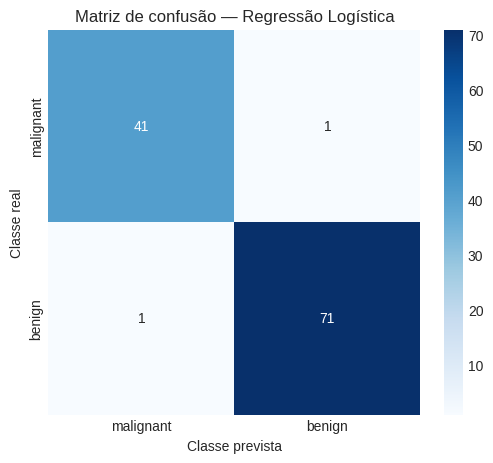

In [ ]:
# Calcular e visualizar a matriz de confusão.
cm_log = confusion_matrix(y_test_c, y_pred_log)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm_log,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=cancer.target_names,
    yticklabels=cancer.target_names
)
plt.xlabel('Classe prevista')
plt.ylabel('Classe real')
plt.title('Matriz de confusão — Regressão Logística')
plt.show()


In [ ]:
# Exibir precision, recall, F1-score e suporte para cada classe.
print(classification_report(
    y_test_c,
    y_pred_log,
    target_names=cancer.target_names,
    digits=4
))


              precision    recall  f1-score   support

   malignant     0.9762    0.9762    0.9762        42
      benign     0.9861    0.9861    0.9861        72

    accuracy                         0.9825       114
   macro avg     0.9812    0.9812    0.9812       114
weighted avg     0.9825    0.9825    0.9825       114



---
## 4. Árvore de Decisão

**O que faz:** aprende regras if/else a partir dos dados. Cada nó é uma decisão, cada folha é uma classe.

**Quando usar:** precisa explicar a decisão para um humano. Visual, interpretável.

**Limitação:** se muito fundo, decora o treino (overfitting). Por isso limitamos a profundidade.

In [ ]:
# Instanciar a Árvore de Decisão com profundidade limitada.
modelo_dt = DecisionTreeClassifier(max_depth=4, random_state=42)

# Treinar a árvore com os dados originais (árvores não precisam de padronização).
modelo_dt.fit(X_train_c, y_train_c)

# Fazer as previsões no conjunto de teste.
y_pred_dt = modelo_dt.predict(X_test_c)

# Avaliar a acurácia e o F1-score.
print(f"Accuracy: {accuracy_score(y_test_c, y_pred_dt):.4f}")
print(f"F1-score: {f1_score(y_test_c, y_pred_dt):.4f}")


Accuracy: 0.9386
F1-score: 0.9510


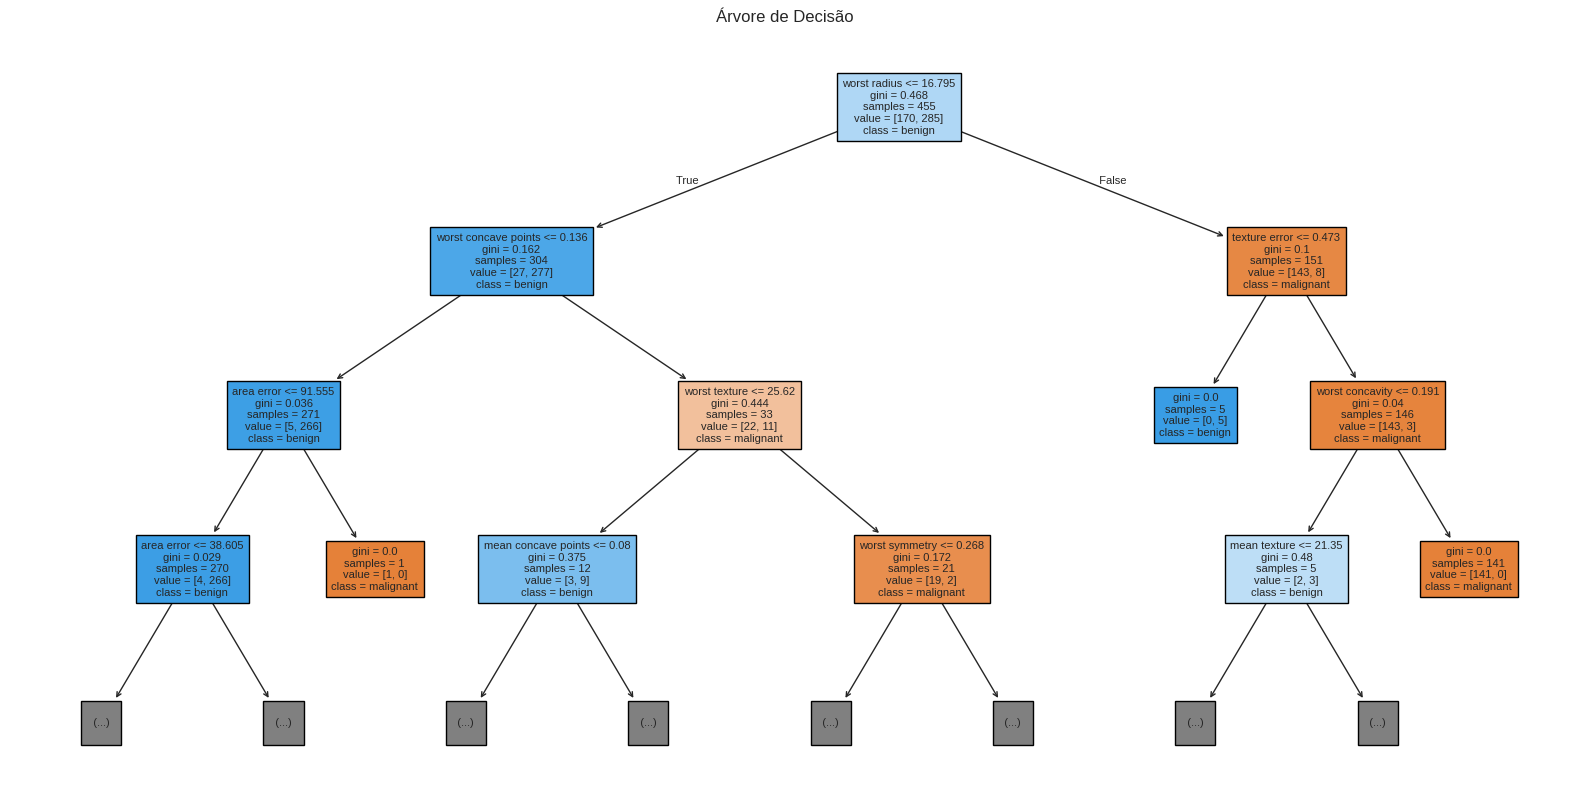

In [ ]:
# Visualizar a árvore limitada às primeiras decisões.
plt.figure(figsize=(20, 10))
plot_tree(
    modelo_dt,
    feature_names=X_cancer.columns,
    class_names=cancer.target_names,
    filled=True,
    max_depth=3,
    fontsize=8
)
plt.title('Árvore de Decisão')
plt.show()


In [ ]:
# Obter a importância de cada feature na árvore.
importancias_dt = pd.Series(
    modelo_dt.feature_importances_,
    index=X_cancer.columns
).sort_values(ascending=False)

# Mostrar somente as 10 features mais importantes.
display(importancias_dt.head(10).to_frame('importancia'))


,importancia
worst radius,0.733548
worst concave points,0.122028
texture error,0.045785
worst texture,0.032319
worst concavity,0.017161
mean concave points,0.013327
area error,0.012704
mean texture,0.011846
worst symmetry,0.011282
mean area,0.000000


**Interpretação:** as features no topo são as que mais contribuíram para a decisão. As features que aparecem no topo do gráfico são as que mais contribuíram para as decisões desta árvore específica.

---
## 5. Random Forest

**O que faz:** treina centenas de árvores em paralelo, cada uma em uma amostra aleatória dos dados. A votação majoritária decide a classe final.

**Quando usar:** quando uma árvore só não basta. Robusto, pouco tuning necessário. Em produção, é o padrão para a maioria dos problemas tabulares.

In [ ]:
# Instanciar o Random Forest com 200 árvores.
modelo_rf = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

# Treinar o ensemble com os dados de treino.
modelo_rf.fit(X_train_c, y_train_c)

# Fazer previsões no conjunto de teste.
y_pred_rf = modelo_rf.predict(X_test_c)
y_prob_rf = modelo_rf.predict_proba(X_test_c)[:, 1]

print(f"Accuracy: {accuracy_score(y_test_c, y_pred_rf):.4f}")
print(f"F1-score: {f1_score(y_test_c, y_pred_rf):.4f}")
print(f"AUC:      {roc_auc_score(y_test_c, y_prob_rf):.4f}")


Accuracy: 0.9561
F1-score: 0.9655
AUC:      0.9931


,importancia
worst perimeter,0.133100
worst area,0.128052
worst concave points,0.108107
mean concave points,0.094414
worst radius,0.090639
mean radius,0.058662
mean perimeter,0.055242
mean area,0.049938
mean concavity,0.046207
worst concavity,0.035357


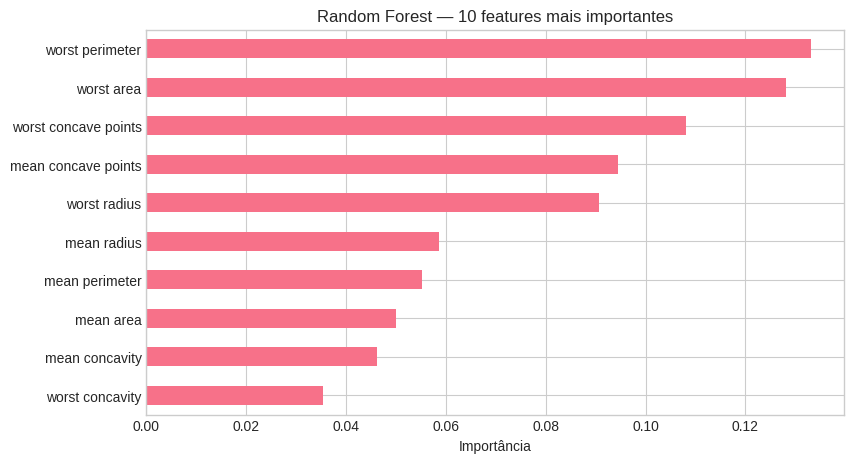

In [ ]:
# Calcular a importância das features no Random Forest.
importancias_rf = pd.Series(
    modelo_rf.feature_importances_,
    index=X_cancer.columns
).sort_values(ascending=False)

# Mostrar as 10 features mais importantes.
display(importancias_rf.head(10).to_frame('importancia'))

# Gráfico das 10 features mais importantes.
plt.figure(figsize=(9, 5))
importancias_rf.head(10).sort_values().plot(kind='barh')
plt.xlabel('Importância')
plt.title('Random Forest — 10 features mais importantes')
plt.show()


**Por que Random Forest é melhor que Árvore única?** Cada árvore vê só parte dos dados. O ensemble captura padrões diferentes e reduz o overfitting. O ganho de desempenho depende do dataset e da configuração dos modelos; não há um percentual fixo.

---
## 6. XGBoost (eXtreme Gradient Boosting)

**O que faz:** treina árvores em **sequência** (boosting). Cada árvore nova corrige o erro da anterior. Campeão da maioria dos benchmarks em dados tabulares.

**Quando usar:** quer a melhor performance em dados tabulares. Requer tuning de hiperparâmetros, mas geralmente vale a pena.

In [ ]:
# Instanciar o XGBoost para classificação binária.
modelo_xgb = XGBClassifier(
    n_estimators=200,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.9,
    colsample_bytree=0.9,
    objective='binary:logistic',
    eval_metric='logloss',
    random_state=42,
    n_jobs=-1
)

# Treinar o XGBoost com os dados de treino.
modelo_xgb.fit(X_train_c, y_train_c)

# Fazer previsões e obter probabilidades.
y_pred_xgb = modelo_xgb.predict(X_test_c)
y_prob_xgb = modelo_xgb.predict_proba(X_test_c)[:, 1]

print(f"Accuracy: {accuracy_score(y_test_c, y_pred_xgb):.4f}")
print(f"F1-score: {f1_score(y_test_c, y_pred_xgb):.4f}")
print(f"AUC:      {roc_auc_score(y_test_c, y_prob_xgb):.4f}")


Accuracy: 0.9474
F1-score: 0.9589
AUC:      0.9950


,importancia
worst perimeter,0.275714
worst radius,0.245979
worst concave points,0.084601
mean concave points,0.059886
worst area,0.031545
concavity error,0.029138
worst compactness,0.026767
mean area,0.023099
texture error,0.022401
worst concavity,0.018565


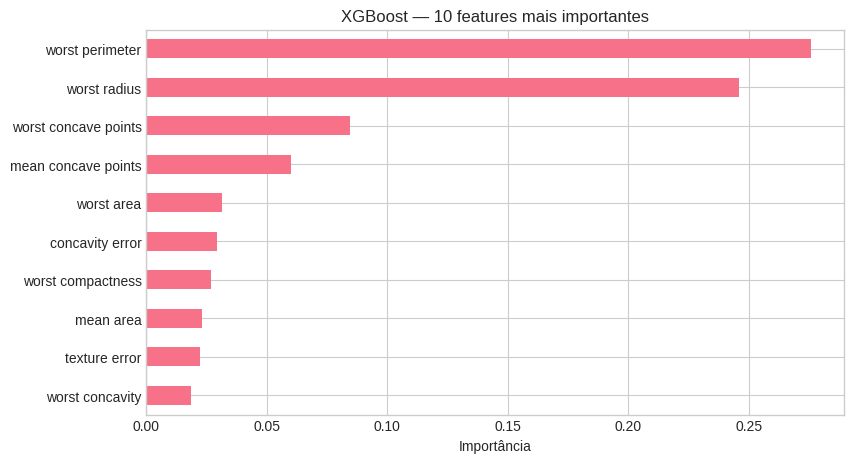

In [ ]:
# Obter a importância das features segundo o XGBoost.
importancias_xgb = pd.Series(
    modelo_xgb.feature_importances_,
    index=X_cancer.columns
).sort_values(ascending=False)

# Mostrar as 10 features mais importantes.
display(importancias_xgb.head(10).to_frame('importancia'))

# Visualizar as 10 maiores importâncias.
plt.figure(figsize=(9, 5))
importancias_xgb.head(10).sort_values().plot(kind='barh')
plt.xlabel('Importância')
plt.title('XGBoost — 10 features mais importantes')
plt.show()


---
## 7. Comparação dos 5 Algoritmos

Vamos colocar todos na mesa e comparar de forma justa. Para a regressão, vamos olhar o R². Para classificação, F1 e AUC.

In [ ]:
# Reunir as métricas dos quatro modelos de classificação.
resultados = pd.DataFrame({
    'Modelo': [
        'Regressão Logística',
        'Árvore de Decisão',
        'Random Forest',
        'XGBoost'
    ],
    'Accuracy': [
        accuracy_score(y_test_c, y_pred_log),
        accuracy_score(y_test_c, y_pred_dt),
        accuracy_score(y_test_c, y_pred_rf),
        accuracy_score(y_test_c, y_pred_xgb)
    ],
    'F1': [
        f1_score(y_test_c, y_pred_log),
        f1_score(y_test_c, y_pred_dt),
        f1_score(y_test_c, y_pred_rf),
        f1_score(y_test_c, y_pred_xgb)
    ],
    'AUC': [
        roc_auc_score(y_test_c, y_prob_log),
        roc_auc_score(y_test_c, modelo_dt.predict_proba(X_test_c)[:, 1]),
        roc_auc_score(y_test_c, y_prob_rf),
        roc_auc_score(y_test_c, y_prob_xgb)
    ]
})

# Ordenar pelo F1-score, do maior para o menor.
resultados = resultados.sort_values('F1', ascending=False).reset_index(drop=True)

display(resultados.round(4))

# Mostrar também o desempenho da Regressão Linear separadamente,
# pois ela resolve um problema de regressão e não pode ser comparada por F1/AUC.
print(f"Regressão Linear — R²: {r2:.4f}")


,Modelo,Accuracy,F1,AUC
0,Regressão Logística,0.9825,0.9861,0.9954
1,Random Forest,0.9561,0.9655,0.9931
2,XGBoost,0.9474,0.9589,0.9950
3,Árvore de Decisão,0.9386,0.9510,0.9342


Regressão Linear — R²: 0.5758


In [ ]:
# Gráfico comparando F1 e AUC dos modelos de classificação.
comparacao = resultados.set_index('Modelo')[['F1', 'AUC']]
comparacao.plot(kind='bar', figsize=(10, 6))
plt.ylim(0.80, 1.01)
plt.ylabel('Pontuação')
plt.title('Comparação dos modelos de classificação')
plt.xticks(rotation=15)
plt.legend(title='Métrica')
plt.show()


In [ ]:
# Validação cruzada com 5 partes para uma estimativa mais robusta do F1-score.
modelos_cv = {
    'Regressão Logística': LogisticRegression(max_iter=5000, random_state=42),
    'Árvore de Decisão': DecisionTreeClassifier(max_depth=4, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1),
    'XGBoost': XGBClassifier(
        n_estimators=200,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.9,
        colsample_bytree=0.9,
        objective='binary:logistic',
        eval_metric='logloss',
        random_state=42,
        n_jobs=-1
    )
}

# Para a Regressão Logística, usamos os dados padronizados.
X_cv_log = StandardScaler().fit_transform(X_cancer)

resultados_cv = []
for nome, modelo in modelos_cv.items():
    if nome == 'Regressão Logística':
        scores = cross_val_score(modelo, X_cv_log, y_cancer, cv=5, scoring='f1')
    else:
        scores = cross_val_score(modelo, X_cancer, y_cancer, cv=5, scoring='f1')
    resultados_cv.append({
        'Modelo': nome,
        'F1 médio': scores.mean(),
        'Desvio padrão': scores.std()
    })

resultados_cv = pd.DataFrame(resultados_cv).sort_values('F1 médio', ascending=False)
display(resultados_cv.round(4))


,Modelo,F1 médio,Desvio padrão
0,Regressão Logística,0.9848,0.0050
3,XGBoost,0.9760,0.0173
2,Random Forest,0.9665,0.0191
1,Árvore de Decisão,0.9368,0.0169


### ✍️ Conclusão da prática

Nesta prática foram aplicados cinco algoritmos de aprendizagem supervisionada: Regressão Linear, Regressão Logística, Árvore de Decisão, Random Forest e XGBoost. A Regressão Linear foi utilizada para prever um valor contínuo no California Housing, enquanto os outros quatro modelos foram usados para classificar tumores no dataset Breast Cancer Wisconsin. A comparação deve considerar as métricas adequadas a cada tarefa, principalmente R² para regressão e F1/AUC para classificação.

Na classificação, o modelo com maior F1 no conjunto de teste e na validação cruzada é o que apresenta melhor resultado dentro desta prática. Isso não significa que ele seja sempre o melhor modelo para outros datasets, pois a escolha depende dos dados, das métricas e do objetivo do problema.


---
## 8. Conclusão - Quando usar cada um

| Algoritmo | Melhor para | Vantagem | Cuidado |
|-----------|-------------|----------|---------|
| **Regressão Linear** | Prever números contínuos | Simples, interpretável, baseline rápido | Só pega relações lineares |
| **Regressão Logística** | Classificação binária | Probabilidade calibrada, coeficientes claros | Assume linearidade no logit |
| **Árvore de Decisão** | Precisa explicar decisão | Visual, regras if/else | Sente overfitting se fundo |
| **Random Forest** | Padrão para dados tabulares | Robusto, pouco tuning | Modelo grande, mais lento |
| **XGBoost** | Melhor performance tabular | Campeão de benchmarks | Requer tuning, mais lento |

### 📚 Regra de bolso

1. **Comece com baseline simples** (Regressão Linear ou Logística).
2. **Se precisar de performance, escale para árvore.**
3. **Se ainda não for suficiente, vá para Random Forest ou XGBoost.**
4. **Só considere Deep Learning se tiver texto, imagem ou áudio.**

### 🎯 Próximos passos

- **Tunar hiperparâmetros** com `GridSearchCV` ou `Optuna`
- **Feature engineering** - criar features novas a partir das existentes
- **Tratar desbalanceamento** com SMOTE, undersampling ou ajuste de peso
- **Monitorar drift** em produção - o mundo muda, o modelo envelhece
- **Combinar modelos** em ensemble (stacking, blending)

### 📖 Leitura recomendada

- Géron, A. (2022). *Mãos à obra: aprendizado de máquina com Scikit-Learn, Keras e TensorFlow*.
- Hastie, T., Tibshirani, R. & Friedman, J. (2009). *The Elements of Statistical Learning*.
- Chen, T. & Guestrin, C. (2016). *XGBoost: A Scalable Tree Boosting System* (KDD '16).

---

**Dúvidas?** Fale com o professor Heuryk Wylk - heuryk.wylk@pe.senac.br

**Glossário rápido:**

- **Feature engineering**: criar features novas a partir das existentes (ex: log da renda, renda por quarto)
- **Drift**: mudança na distribuição dos dados ao longo do tempo (modelo envelhece)
- **SMOTE**: técnica para gerar exemplos sintéticos em classes desbalanceadas
- **Stacking**: usar a saída de vários modelos como entrada de um modelo 'meta'